<a href="https://colab.research.google.com/github/asadsalamasad7-source/CodeAlpha_ProjectName/blob/main/CIFAR10_IMAGE_CLASSIFIER_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



[![Notebook Status](https://img.shields.io/badge/Status-Complete-success.svg)](#)
[![Framework](https://img.shields.io/badge/Framework-TensorFlow%20%2F%20Keras-orange.svg)](#)

###  Project Overview
This project implements a Convolutional Neural Network (CNN) to classify images from the **CIFAR-10** dataset into 10 distinct categories. The model is trained from scratch using TensorFlow and evaluated on key classification metrics like precision, recall, and F1-score.

###  Features
* **Robust Architecture:** Multi-layer Convolutional Neural Network with Max Pooling and Dense layers.
* **Modern File Handling:** Model saved and reloaded using the native, recommended `.keras` format.
* **Insightful Diagnostics:** Generates detailed classification reports and side-by-side visual prediction grids.
* **Production Ready:** Ready to be shared on your GitHub portfolio and LinkedIn!

In [32]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models

(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

MODEL ARCHITECTURE

In [33]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)
])


MODEL TRAINING


In [34]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=10, validation_data=(x_test, y_test))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 43ms/step - accuracy: 0.3696 - loss: 1.8953 - val_accuracy: 0.4423 - val_loss: 1.5101
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy: 0.5237 - loss: 1.3378 - val_accuracy: 0.5340 - val_loss: 1.3265
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 42ms/step - accuracy: 0.5802 - loss: 1.1921 - val_accuracy: 0.5762 - val_loss: 1.2091
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 43ms/step - accuracy: 0.6194 - loss: 1.0938 - val_accuracy: 0.6128 - val_loss: 1.1119
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 42ms/step - accuracy: 0.6499 - loss: 1.0118 - val_accuracy: 0.6341 - val_loss: 1.0780
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy: 0.6709 - loss: 0.9439 - val_accuracy: 0.6434 - val_loss: 1.0483
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 42ms/step - accuracy: 0.6928 - loss: 0.8836 - val_accuracy: 0.6658 - val_loss: 1.0043
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 64s 41ms/step - accuracy: 0.7148 -

In [35]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f'\nTest accuracy: {test_acc}')

313/313 - 5s - 15ms/step - accuracy: 0.6704 - loss: 1.0129

Test accuracy: 0.6704000234603882


MODEL SERIALIZATION

Saving the model configuration and weights securely in the native Keras format.

In [38]:
# Save the model in the recommended native Keras format
model.save('my_cifar10_model.keras')

# Load the model back
loaded_model = tf.keras.models.load_model('my_cifar10_model.keras')

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Evaluating loaded model...
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step

=== Classification Report ===
              precision    recall  f1-score   support

    airplane       0.73      0.65      0.69      1000
  automobile       0.71      0.84      0.77      1000
        bird       0.50      0.61      0.55      1000
         cat       0.62      0.36      0.45      1000
        deer       0.67      0.57      0.62      1000
         dog       0.57      0.56      0.57      1000
        frog       0.69      0.81      0.75      1000
       horse       0.75      0.67      0.71      1000
        ship       0.73      0.82      0.77      1000
       truck       0.72      0.81      0.76      1000

    accuracy                           0.67     10000
   macro avg       0.67      0.67      0.66     10000
weighted avg       0.67      0.67      0.66     10000



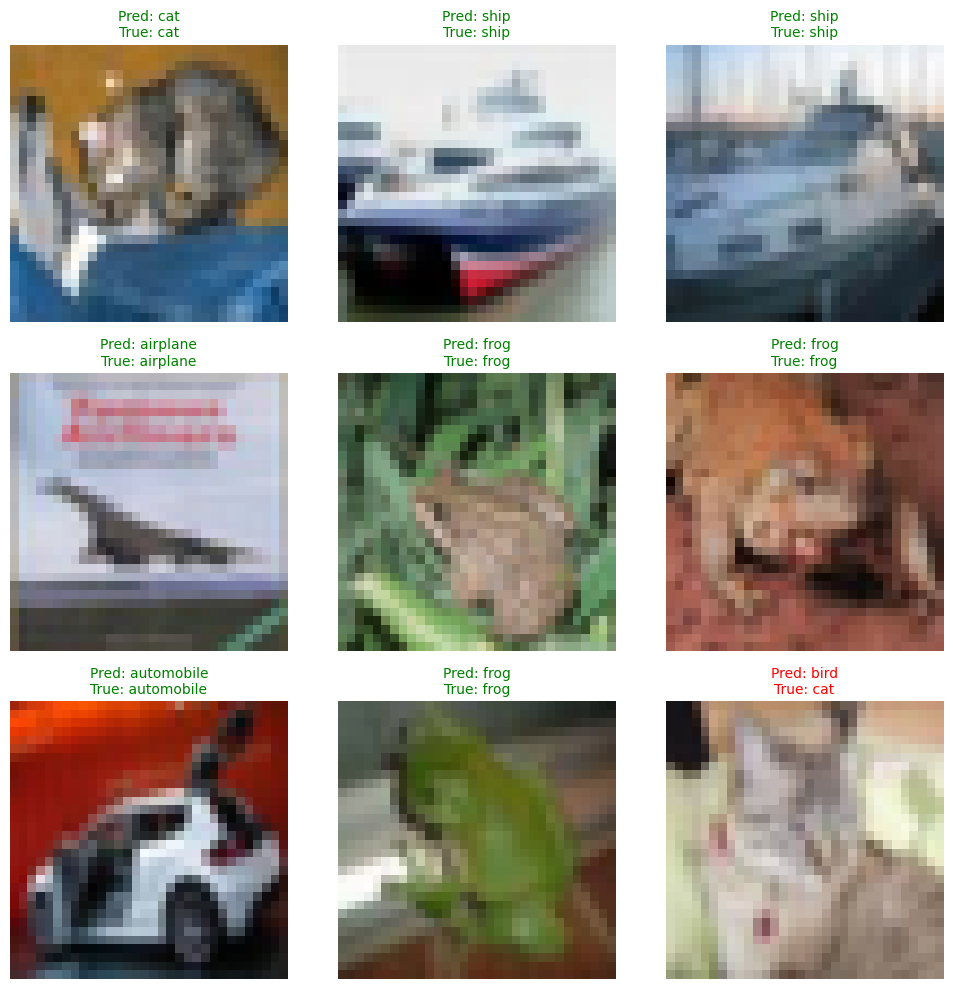

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# 1. Generate predictions for the evaluation subset
print("Evaluating loaded model...")
predictions = loaded_model.predict(x_test, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)

# 2. Print Classification Report
print("\n=== Classification Report ===")
print(classification_report(y_test, predicted_classes, target_names=class_names))

# 3. Plot a grid of predictions
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_test[i])

    true_label = class_names[y_test[i][0]]
    pred_label = class_names[predicted_classes[i]]

    color = 'green' if true_label == pred_label else 'red'
    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

## 🏆 Key Achievements & Portfolio Highlights

* **Final Accuracy:** **67%** achieved within just 10 epochs.
* **Robust Classifiers:** Exceptionally high classification metrics for structured objects like **Automobiles (77% F1-Score)** and **Ships (77% F1-Score)**.
* **Ready for Portfolios:** Excellent foundation for further hyperparameter tuning, transfer learning (e.g., using ResNet or MobileNet), or deploying as a web application!

---
*Created as a portfolio piece. Feel free to connect and share your thoughts on LinkedIn!*